In [1]:
# ==============================================================================
# Cell 1: Environment Setup
# ==============================================================================
!pip install -q transformers accelerate albumentations scikit-learn

import os, gc, random
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from transformers import AutoImageProcessor, AutoModel

os.environ["TOKENIZERS_PARALLELISM"] = "false"

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
print("Environment ready.")

Environment ready.


In [3]:
# ==============================================================================
# Cell 2: Config + Data Loading + Leakage Check
# ==============================================================================
class Config:
    SEED = 42
    DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    USE_CUDA = torch.cuda.is_available()
    N_CPUS = min(4, os.cpu_count() or 2)

    MODEL_ID = "microsoft/rad-dino"
    IMG_SIZE = 224            # must be a multiple of 14 (patch size); 518 = native but slower
    BATCH_SIZE = 64           # feature extraction batch size

    # Head training (on cached features)
    HEAD_BS = 256
    HEAD_EPOCHS = 60
    PATIENCE = 8
    HEAD_LR = 1e-3
    WEIGHT_DECAY = 1e-2
    DROPOUT = 0.35
    HIDDEN = 256
    N_HEAD_SEEDS = 3          # ensemble of heads

    MIN_TP_RETENTION = 0.74   # tau chosen on VAL to keep >= 74% of true positives

    # ---- fixed dataset paths ----
    BASE = Path("/kaggle/input/datasets/prahladgarg/rsna-roi-images")
    SAVED_DIR = BASE / "saved" / "saved"
    CROPS_DIR = BASE / "roi_crops" / "roi_crops"

    WORK_DIR = Path("/kaggle/working")
    OUT_DIR = WORK_DIR / "outputs"

Config.OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- load metadata (first CSV that has the required columns) ----
REQUIRED = {"crop_path", "label", "split"}
df, METADATA_PATH = None, None
for name in ["roi_metadata.csv", "metadata.csv"]:
    p = Config.SAVED_DIR / name
    if not p.exists():
        print(f"[missing] {p}")
        continue
    cols = list(pd.read_csv(p, nrows=5).columns)
    if REQUIRED <= set(cols):
        METADATA_PATH, df = p, pd.read_csv(p)
        print(f"[using]   {p}")
        break
    print(f"[skip]    {p} | columns: {cols}")

if df is None:
    raise ValueError(f"Neither CSV has all of {REQUIRED}. See the columns printed above.")

print("Columns:", list(df.columns))
print("Split values:", df["split"].value_counts().to_dict())

if "conf" not in df.columns:
    print("WARNING: no 'conf' column found, using 1.0 (fusion will reduce to verifier-only).")
    df["conf"] = 1.0

# ---- resolve image paths from the split folders (no recursive search) ----
split_maps = {}
for s in ["train", "val", "test"]:
    d = Config.CROPS_DIR / s
    split_maps[s] = {f: str(d / f) for f in os.listdir(d)} if d.is_dir() else {}
    print(f"{s:5s} crop folder: {len(split_maps[s])} files")

def resolve_path(row):
    return split_maps.get(row["split"], {}).get(Path(str(row["crop_path"])).name)

n_before = len(df)
df["resolved_path"] = df.apply(resolve_path, axis=1)
df = df[df["resolved_path"].notna()].reset_index(drop=True)
df["crop_path"] = df["resolved_path"]
df["label"] = df["label"].astype(int)
print(f"Resolved {len(df)}/{n_before} crops.")
assert len(df) > 0, "No crops resolved: check that crop_path filenames match the files in roi_crops/<split>/."

# ---- leakage check: the same patient/image must not appear in multiple splits ----
group_col = next((c for c in ["patient_id", "patientId", "image_id", "study_id"] if c in df.columns), None)
if group_col:
    sets = {s: set(df.loc[df.split == s, group_col]) for s in ["train", "val", "test"]}
    for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
        ov = len(sets[a] & sets[b])
        print(f"Overlap on '{group_col}' {a}/{b}: {ov}" + ("   <-- LEAKAGE!" if ov else ""))
else:
    print("No patient/image id column found: cannot verify split leakage. Make sure the split is by patient.")

# ---- clean borderline IoU crops in TRAIN only (val/test stay realistic) ----
if "iou" in df.columns:
    train_df = df[(df.split == "train") & ((df.iou <= 0.15) | (df.iou >= 0.40))].reset_index(drop=True)
else:
    train_df = df[df.split == "train"].reset_index(drop=True)
val_df = df[df.split == "val"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):6d} crops | positives: {d.label.mean():.3f}")

[using]   /kaggle/input/datasets/prahladgarg/rsna-roi-images/saved/saved/roi_metadata.csv
Columns: ['crop_path', 'patientId', 'split', 'conf', 'iou', 'label']
Split values: {'train': 44093, 'val': 8713, 'test': 8665}
train crop folder: 44093 files
val   crop folder: 8713 files
test  crop folder: 8665 files
Resolved 61471/61471 crops.
Overlap on 'patientId' train/val: 0
Overlap on 'patientId' train/test: 0
Overlap on 'patientId' val/test: 0
train:  44093 crops | positives: 0.424
val  :   8713 crops | positives: 0.292
test :   8665 crops | positives: 0.290


In [4]:
# ==============================================================================
# Cell 3: Preprocessing (aspect-preserving resize + pad, no center-crop)
# ==============================================================================
processor = AutoImageProcessor.from_pretrained(Config.MODEL_ID)
MEAN, STD, S = processor.image_mean, processor.image_std, Config.IMG_SIZE

base_tf = A.Compose([
    A.LongestMaxSize(max_size=S),
    A.PadIfNeeded(min_height=S, min_width=S, border_mode=cv2.BORDER_CONSTANT),
    A.Normalize(mean=MEAN, std=STD),
])

# mild augmentation, used to build one extra "view" of the training set
aug_tf = A.Compose([
    A.Affine(scale=(0.95, 1.05), translate_percent=(-0.04, 0.04), rotate=(-8, 8), p=0.8),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
])

class CropDataset(Dataset):
    def __init__(self, paths, flip=False, aug=None):
        self.paths, self.flip, self.aug = list(paths), flip, aug

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        if self.flip:
            img = cv2.flip(img, 1)
        if self.aug is not None:
            img = self.aug(image=img)["image"]
        img = base_tf(image=img)["image"]
        return torch.from_numpy(img).permute(2, 0, 1).float()

preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

In [12]:
# ==============================================================================
# Cell 4: Fine-tuning setup (model, loaders, optimizer)
# ==============================================================================
import math, time

Config.EPOCHS = 8
Config.FT_BATCH = 32
Config.FT_PATIENCE = 3
Config.UNFREEZE_BLOCKS = 6      # last N transformer blocks are fine-tuned (0 = frozen backbone)
Config.LR_HEAD = 3e-4
Config.LR_BACKBONE = 2e-5

class LabeledCrops(Dataset):
    def __init__(self, d, train):
        self.paths = d.crop_path.tolist()
        self.labels = d.label.values.astype("float32")
        self.train = train
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.paths[i]), cv2.COLOR_BGR2RGB)
        if self.train:
            if random.random() < 0.5:
                img = cv2.flip(img, 1)
            img = aug_tf(image=img)["image"]
        img = base_tf(image=img)["image"]
        return torch.from_numpy(img).permute(2, 0, 1).float(), torch.tensor(self.labels[i])

def make_loader(d, train):
    return DataLoader(LabeledCrops(d, train), batch_size=Config.FT_BATCH, shuffle=train,
                      num_workers=Config.N_CPUS, pin_memory=Config.USE_CUDA,
                      drop_last=False, persistent_workers=Config.N_CPUS > 0)

train_loader, val_loader, test_loader = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)
y_val, y_test = val_df.label.values, test_df.label.values

class RADDINOClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(Config.MODEL_ID)
        d = self.encoder.config.hidden_size
        for p in self.encoder.parameters():
            p.requires_grad = False
        if Config.UNFREEZE_BLOCKS > 0:
            for blk in self.encoder.encoder.layer[-Config.UNFREEZE_BLOCKS:]:
                for p in blk.parameters():
                    p.requires_grad = True
            for p in self.encoder.layernorm.parameters():
                p.requires_grad = True
        self.head = nn.Sequential(
            nn.LayerNorm(2 * d), nn.Dropout(Config.DROPOUT),
            nn.Linear(2 * d, Config.HIDDEN), nn.GELU(),
            nn.Dropout(Config.DROPOUT / 2), nn.Linear(Config.HIDDEN, 1),
        )
    def forward(self, x):
        h = self.encoder(pixel_values=x).last_hidden_state
        return self.head(torch.cat([h[:, 0], h[:, 1:].mean(dim=1)], dim=1)).squeeze(-1)

model = RADDINOClassifier().to(Config.DEVICE)
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable params: {n_train/1e6:.2f}M / {n_total/1e6:.2f}M")

pos = max(1, int((train_df.label == 1).sum())); neg = int((train_df.label == 0).sum())
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=Config.DEVICE))

bb_params = [p for p in model.encoder.parameters() if p.requires_grad]
groups = [{"params": model.head.parameters(), "lr": Config.LR_HEAD}]
if bb_params:
    groups.append({"params": bb_params, "lr": Config.LR_BACKBONE})
optimizer = torch.optim.AdamW(groups, weight_decay=Config.WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
total_steps, warm = Config.EPOCHS * steps_per_epoch, steps_per_epoch   # 1 epoch warmup, then cosine
def lr_lambda(s):
    if s < warm:
        return (s + 1) / warm
    return max(0.01, 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total_steps - warm))))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=Config.USE_CUDA)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Trainable params: 42.93M / 86.98M


In [13]:
# ==============================================================================
# Cell 5: Training loop (epoch-wise results) + predictions for fusion
# ==============================================================================
dev_type = "cuda" if Config.USE_CUDA else "cpu"
trainable_names = {n for n, p in model.named_parameters() if p.requires_grad}
best_path = Config.OUT_DIR / "rad_dino_finetuned_best.pt"

@torch.no_grad()
def evaluate(loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with torch.autocast(device_type=dev_type, enabled=Config.USE_CUDA):
            out = model(x.to(Config.DEVICE, non_blocking=True))
        logits.append(out.float().cpu()); labels.append(y)
    logits, labels = torch.cat(logits), torch.cat(labels)
    loss = criterion(logits.to(Config.DEVICE), labels.to(Config.DEVICE)).item()
    return logits.numpy(), labels.numpy(), loss

history = {"train_loss": [], "val_loss": [], "val_auc": [], "val_ap": []}
best_ap, best_state, bad = -1.0, None, 0

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>8} | {'Val AUC':>7} | {'Val AP':>6} | {'LR(head)':>9} | {'Time':>6}")
print("-" * 70)

for epoch in range(1, Config.EPOCHS + 1):
    t0 = time.time()
    model.train()
    running, seen = 0.0, 0
    bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{Config.EPOCHS}", leave=False)
    for x, y in bar:
        x, y = x.to(Config.DEVICE, non_blocking=True), y.to(Config.DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=dev_type, enabled=Config.USE_CUDA):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        running += loss.item() * len(y); seen += len(y)
        bar.set_postfix(loss=f"{running / seen:.4f}")

    v_logit, v_lab, v_loss = evaluate(val_loader)
    auc = roc_auc_score(v_lab, v_logit) if len(np.unique(v_lab)) > 1 else 0.5
    ap = average_precision_score(v_lab, v_logit)
    history["train_loss"].append(running / seen); history["val_loss"].append(v_loss)
    history["val_auc"].append(auc); history["val_ap"].append(ap)

    star = ""
    if ap > best_ap:
        best_ap, bad, star = ap, 0, "  <- best"
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in trainable_names}
        torch.save(best_state, best_path)
    else:
        bad += 1

    print(f"{epoch:5d} | {running/seen:10.4f} | {v_loss:8.4f} | {auc:7.4f} | {ap:6.4f} | "
          f"{optimizer.param_groups[0]['lr']:9.2e} | {time.time()-t0:5.0f}s{star}")

    if bad >= Config.FT_PATIENCE:
        print(f"Early stopping at epoch {epoch} (no val AP improvement for {Config.FT_PATIENCE} epochs).")
        break

# ---- restore best weights, produce logits for the fusion cell ----
model.load_state_dict(best_state, strict=False)
val_logit, _, _ = evaluate(val_loader)
test_logit, _, _ = evaluate(test_loader)
hists = [history]

print("\n" + "=" * 50)
print(f"BEST (val)  AUC: {roc_auc_score(y_val, val_logit):.4f} | AP: {average_precision_score(y_val, val_logit):.4f}")
print(f"TEST        AUC: {roc_auc_score(y_test, test_logit):.4f} | AP: {average_precision_score(y_test, test_logit):.4f}")
print("=" * 50)

gc.collect(); torch.cuda.empty_cache()

Epoch | Train Loss | Val Loss | Val AUC | Val AP |  LR(head) |   Time
----------------------------------------------------------------------


Epoch 01/8:   0%|          | 0/1378 [00:00<?, ?it/s]

    1 |     0.6253 |   0.6608 |  0.7596 | 0.5784 |  3.00e-04 |   447s  <- best


Epoch 02/8:   0%|          | 0/1378 [00:00<?, ?it/s]

    2 |     0.5171 |   0.7046 |  0.7607 | 0.5877 |  2.85e-04 |   447s  <- best


Epoch 03/8:   0%|          | 0/1378 [00:00<?, ?it/s]

    3 |     0.4000 |   0.7640 |  0.7405 | 0.5681 |  2.44e-04 |   446s


Epoch 04/8:   0%|          | 0/1378 [00:00<?, ?it/s]

    4 |     0.2853 |   0.9838 |  0.7295 | 0.5619 |  1.83e-04 |   444s


Epoch 05/8:   0%|          | 0/1378 [00:00<?, ?it/s]

    5 |     0.2018 |   1.2831 |  0.7364 | 0.5665 |  1.17e-04 |   443s
Early stopping at epoch 5 (no val AP improvement for 3 epochs).

BEST (val)  AUC: 0.7607 | AP: 0.5877
TEST        AUC: 0.7881 | AP: 0.6113


In [7]:
# ==============================================================================
# Cell 6: Fusion + Threshold Selection on VAL + Final Test Evaluation
# ==============================================================================
def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def pick_tau(score, y, min_tp_ret=Config.MIN_TP_RETENTION):
    """Highest threshold that still keeps >= min_tp_ret of the true positives."""
    pos_scores = np.sort(score[y == 1])
    k = int(np.floor((1 - min_tp_ret) * len(pos_scores)))
    return pos_scores[k]

def summarize(name, score, y, tau):
    keep = score >= tau
    tp0, fp0 = int((y == 1).sum()), int((y == 0).sum())
    tp, fp = int((keep & (y == 1)).sum()), int((keep & (y == 0)).sum())
    return {
        "score": name, "tau": round(float(tau), 4),
        "retained": int(keep.sum()),
        "FP_reduction_%": round(100 * (fp0 - fp) / max(fp0, 1), 2),
        "TP_retention_%": round(100 * tp / max(tp0, 1), 2),
        "precision_before": round(tp0 / len(y), 4),
        "precision_after": round(tp / max(int(keep.sum()), 1), 4),
        "AUC": round(roc_auc_score(y, score), 4),
        "AP": round(average_precision_score(y, score), 4),
    }

conf_val, conf_test = val_df.conf.values, test_df.conf.values

# three candidate scores
scores_val, scores_test = {}, {}
scores_val["detector conf only (baseline)"] = conf_val
scores_test["detector conf only (baseline)"] = conf_test

scores_val["conf x RAD-DINO prob"] = conf_val / (1 + np.exp(-val_logit)) * 1.0
scores_test["conf x RAD-DINO prob"] = conf_test / (1 + np.exp(-test_logit)) * 1.0
# (the line above is conf * sigmoid(logit))

# learned fusion: logistic regression on [logit(conf), verifier logit]; out-of-fold on val for tau selection
Fv = np.c_[logit(conf_val), val_logit]
Ft = np.c_[logit(conf_test), test_logit]
lr = LogisticRegression(C=1.0, max_iter=1000)
oof = cross_val_predict(lr, Fv, y_val, cv=5, method="predict_proba")[:, 1]
lr.fit(Fv, y_val)
scores_val["learned fusion (LR)"] = oof
scores_test["learned fusion (LR)"] = lr.predict_proba(Ft)[:, 1]
print("Fusion weights [conf, verifier]:", lr.coef_.round(3), "bias:", lr.intercept_.round(3))

rows = []
for name in scores_val:
    tau = pick_tau(scores_val[name], y_val)          # chosen on VAL only
    rows.append(summarize(name, scores_test[name], y_test, tau))   # applied once to TEST


# Add comparison thresholds matching Slide 7 & 8
for fixed_tau in [0.10, 0.20, 0.30]:
    rows.append(summarize(f"conf x RAD-DINO (fixed tau={fixed_tau})", 
                          scores_test["conf x RAD-DINO prob"], y_test, fixed_tau))


results = pd.DataFrame(rows).set_index("score")
print("\n" + "=" * 100)
print(f"TEST RESULTS  (threshold chosen on val to keep >= {Config.MIN_TP_RETENTION:.0%} of true positives)")
print("=" * 100)
print(results.to_string())



# save per-proposal results
out = test_df.copy()
out["rad_dino_logit"] = test_logit
out["rad_dino_prob"] = 1 / (1 + np.exp(-test_logit))
out["fused_product"] = scores_test["conf x RAD-DINO prob"]
out["fused_learned"] = scores_test["learned fusion (LR)"]
out.to_csv(Config.OUT_DIR / "rad_dino_test_results.csv", index=False)
results.to_csv(Config.OUT_DIR / "rad_dino_summary.csv")

Fusion weights [conf, verifier]: [[1.305 0.358]] bias: [0.673]

TEST RESULTS  (threshold chosen on val to keep >= 74% of true positives)
                                    tau  retained  FP_reduction_%  TP_retention_%  precision_before  precision_after     AUC      AP
score                                                                                                                               
detector conf only (baseline)    0.2261      4182           63.86           77.92            0.2901           0.4684  0.7855  0.6015
conf x RAD-DINO prob             0.0797      4194           64.44           79.83            0.2901           0.4785  0.8057  0.6343
learned fusion (LR)              0.2475      4080           66.07           79.28            0.2901           0.4885  0.8076  0.6377
conf x RAD-DINO (fixed tau=0.1)  0.1000      3564           72.36           74.14            0.2901           0.5230  0.8057  0.6343
conf x RAD-DINO (fixed tau=0.2)  0.2000      1854           89.84

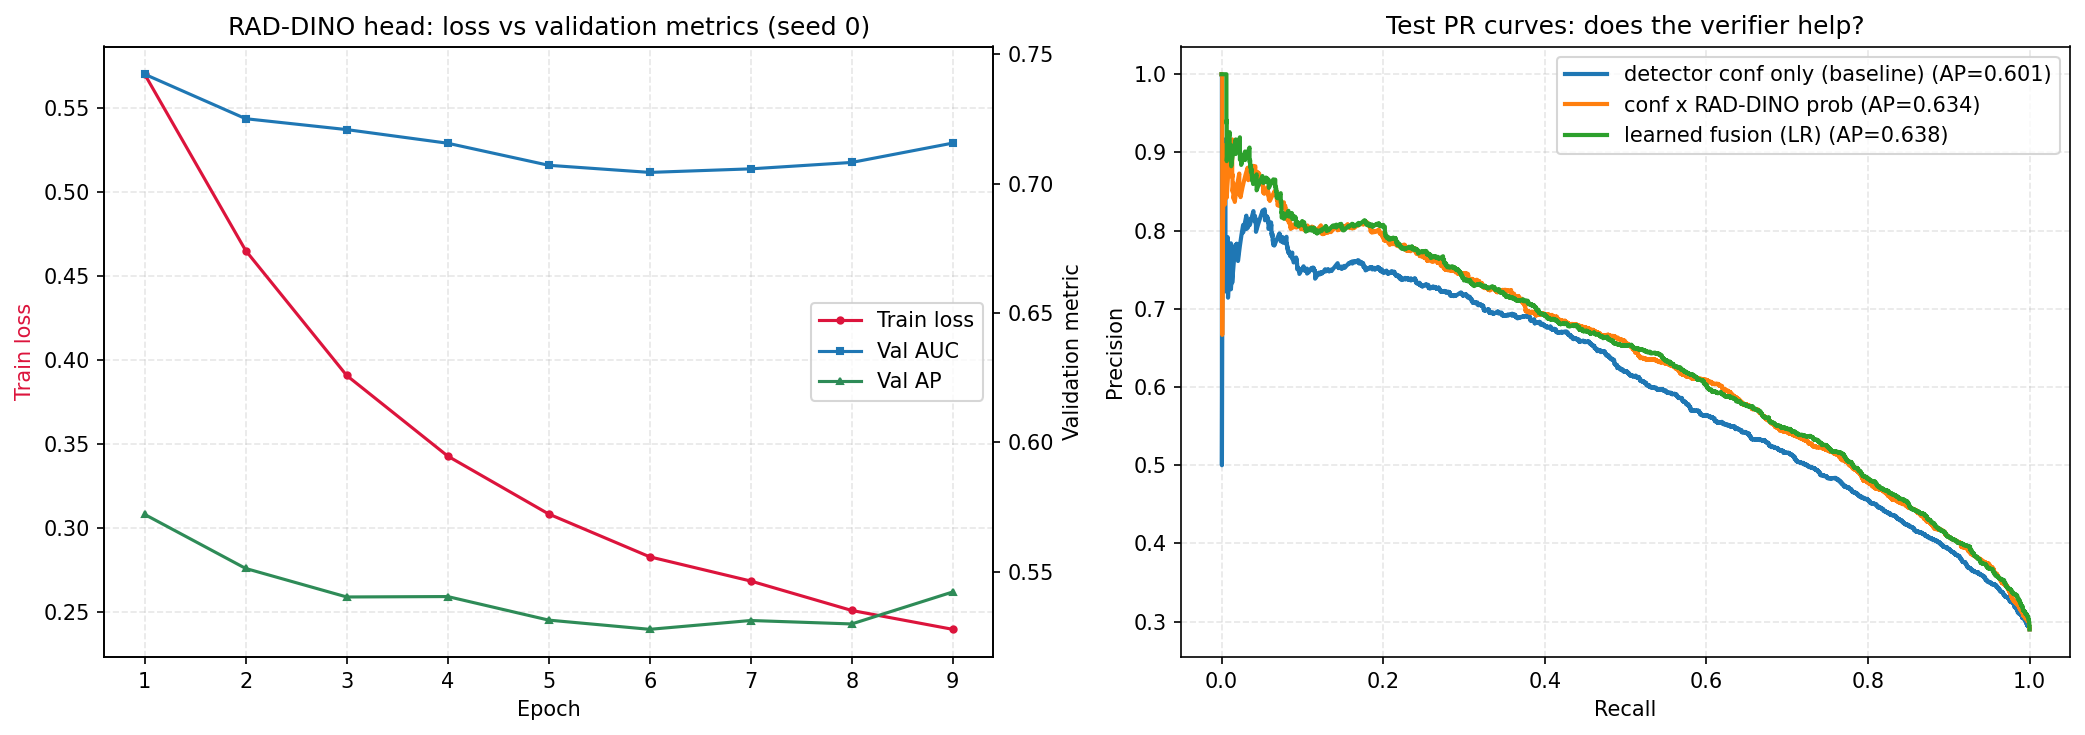

In [8]:
# ==============================================================================
# Cell 7: Plots (training curves + PR curves)
# ==============================================================================
h = hists[0]
ep = np.arange(1, len(h["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

ax1 = axes[0]
l1 = ax1.plot(ep, h["train_loss"], color="crimson", marker="o", ms=3, label="Train loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Train loss", color="crimson")
ax1.grid(True, ls="--", alpha=0.3)
ax2 = ax1.twinx()
l2 = ax2.plot(ep, h["val_auc"], color="#1f77b4", marker="s", ms=3, label="Val AUC")
l3 = ax2.plot(ep, h["val_ap"], color="seagreen", marker="^", ms=3, label="Val AP")
ax2.set_ylabel("Validation metric")
ax1.legend(l1 + l2 + l3, [l.get_label() for l in l1 + l2 + l3], loc="center right")
ax1.set_title("RAD-DINO head: loss vs validation metrics (seed 0)")

ax = axes[1]
for name, s in scores_test.items():
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, lw=2, label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.grid(True, ls="--", alpha=0.3)
ax.set_title("Test PR curves: does the verifier help?"); ax.legend()

plt.tight_layout()
plt.savefig(Config.OUT_DIR / "rad_dino_curves.png", dpi=300)
plt.show()

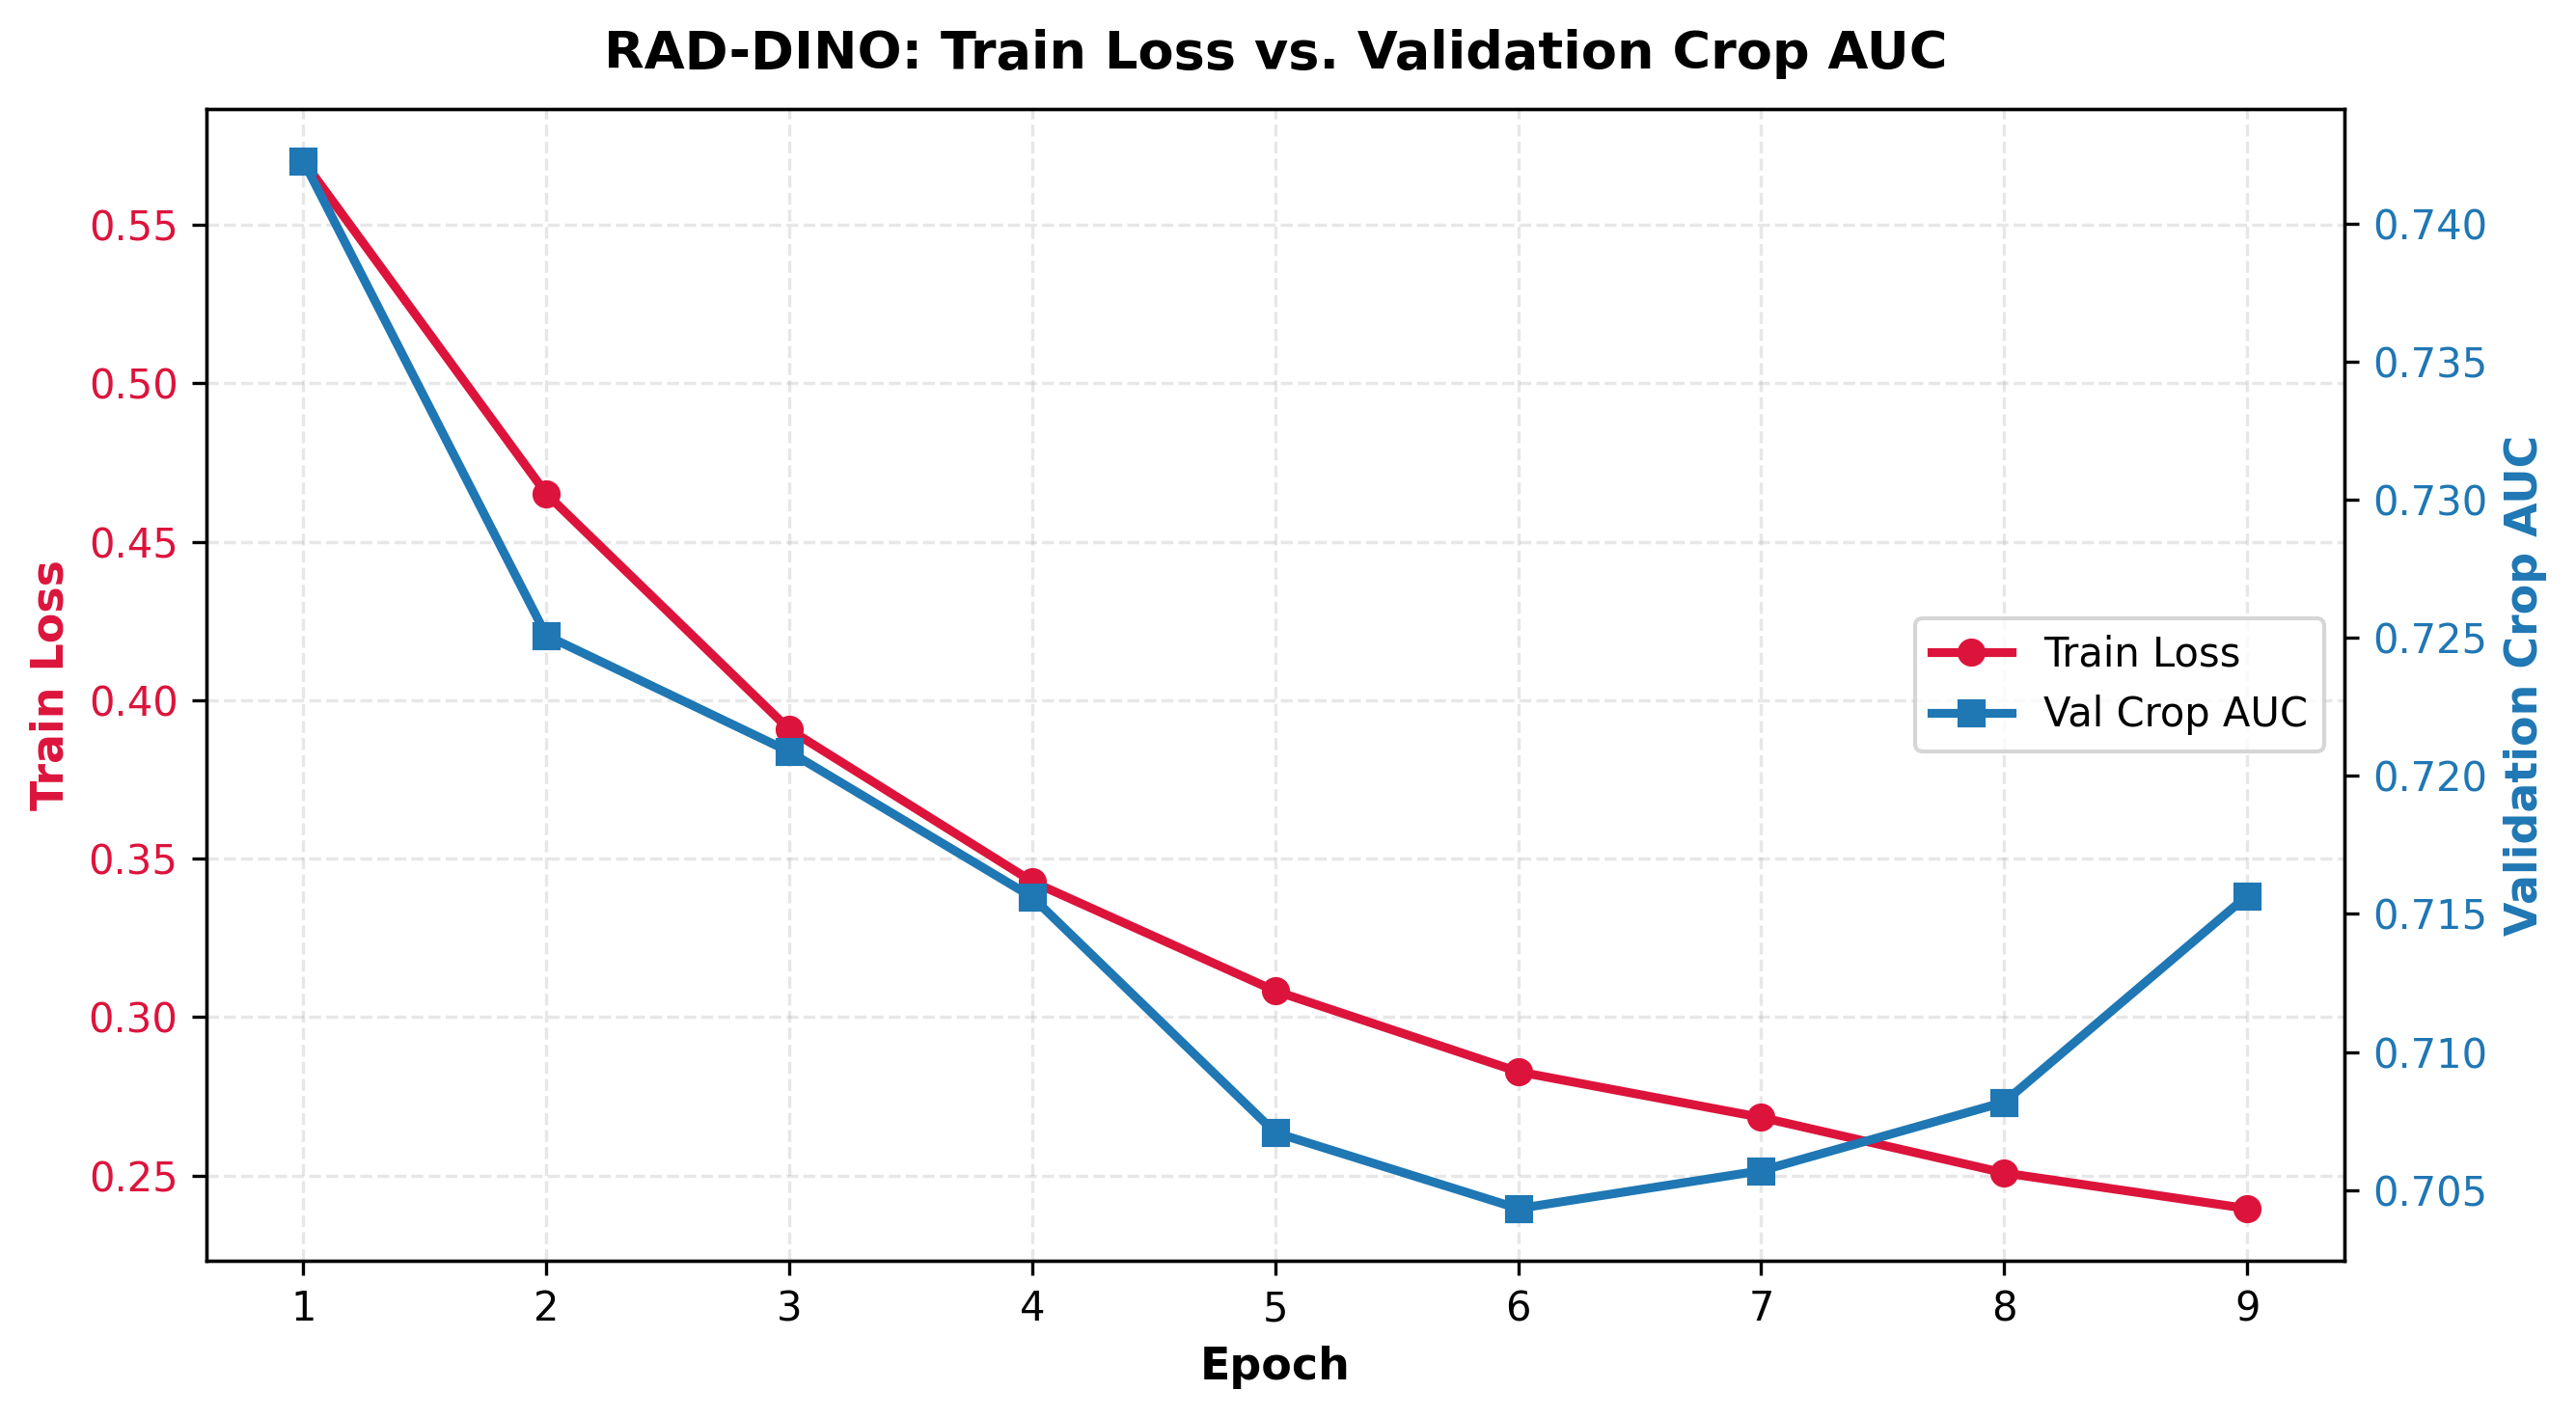

In [9]:
# ==============================================================================
# Cell 8: Dual-Axis Performance Curve (Slide 7 & 12 Style)
# ==============================================================================
history = hists[0]
epochs_range = np.arange(1, len(history["train_loss"]) + 1)

fig, ax1 = plt.subplots(figsize=(9, 5), dpi=300)

ax1.set_xlabel("Epoch", fontsize=11, fontweight="bold")
ax1.set_ylabel("Train Loss", color="crimson", fontsize=11, fontweight="bold")
line1 = ax1.plot(epochs_range, history["train_loss"], color="crimson", linewidth=2.2, marker="o", label="Train Loss")
ax1.tick_params(axis="y", labelcolor="crimson")
ax1.grid(True, linestyle="--", alpha=0.3)

ax2 = ax1.twinx()
ax2.set_ylabel("Validation Crop AUC", color="#1f77b4", fontsize=11, fontweight="bold")
line2 = ax2.plot(epochs_range, history["val_auc"], color="#1f77b4", linewidth=2.2, marker="s", label="Val Crop AUC")
ax2.tick_params(axis="y", labelcolor="#1f77b4")

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right", frameon=True)

plt.title("RAD-DINO: Train Loss vs. Validation Crop AUC", fontsize=13, pad=10, fontweight="bold")
plt.tight_layout()
plt.savefig(Config.WORK_DIR / "rad_dino_loss_auc_curve.png", dpi=300)
plt.show()